# Pattern Mining

## 0) Setup and inputs
In this notebook we will mine frequent itemsets and association rules from the prepared BoardGameGeek dataset.

Pipeline (high-level):
1. Load prepared data (`df_prepared.csv`)
2. Define transactions (one game = one transaction)
3. Transform attributes into items (attribute=value)
4. Mine frequent itemsets (Apriori or FP-Growth)
5. Generate and rank association rules


In [1]:
# 0) Setup and inputs
import numpy as np
import pandas as pd

from pathlib import Path

pd.set_option("display.max_columns", 200)
pd.set_option("display.max_rows", 200)

# Reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Paths
DATA_PATH = Path("df_prepared.csv")  # <-- update if your notebook is in a different folder

# Key columns
ID_COL = "BGGId"
TARGET_COL = "Rating"  # excluded from mining inputs (used only later for interpretation/validation)

print("Setup complete")
print("DATA_PATH:", DATA_PATH.resolve())


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.4.0 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "C:\Users\hajar\anaconda3\Lib\site-packages\ipykernel_launcher.py", line 17, in <module>
    app.launch_new_instance()
  File "C:\Users\hajar\anaconda3\Lib\site-packages\traitlets\config\application.py", line 1075, in launch_instance
    app.start()
  File "C:\Users\hajar\anaconda3\Lib\site-packages\ipykernel\kernelapp.py", line 701, in start
    self.io_loop.start()
  File "C:\Users\hajar\anaconda3\Lib\site-pack

ImportError: 
A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.4.0 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.




A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.4.0 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "C:\Users\hajar\anaconda3\Lib\site-packages\ipykernel_launcher.py", line 17, in <module>
    app.launch_new_instance()
  File "C:\Users\hajar\anaconda3\Lib\site-packages\traitlets\config\application.py", line 1075, in launch_instance
    app.start()
  File "C:\Users\hajar\anaconda3\Lib\site-packages\ipykernel\kernelapp.py", line 701, in start
    self.io_loop.start()
  File "C:\Users\hajar\anaconda3\Lib\site-pack

ImportError: 
A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.4.0 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.




A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.4.0 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "C:\Users\hajar\anaconda3\Lib\site-packages\ipykernel_launcher.py", line 17, in <module>
    app.launch_new_instance()
  File "C:\Users\hajar\anaconda3\Lib\site-packages\traitlets\config\application.py", line 1075, in launch_instance
    app.start()
  File "C:\Users\hajar\anaconda3\Lib\site-packages\ipykernel\kernelapp.py", line 701, in start
    self.io_loop.start()
  File "C:\Users\hajar\anaconda3\Lib\site-pack

AttributeError: _ARRAY_API not found


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.4.0 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "C:\Users\hajar\anaconda3\Lib\site-packages\ipykernel_launcher.py", line 17, in <module>
    app.launch_new_instance()
  File "C:\Users\hajar\anaconda3\Lib\site-packages\traitlets\config\application.py", line 1075, in launch_instance
    app.start()
  File "C:\Users\hajar\anaconda3\Lib\site-packages\ipykernel\kernelapp.py", line 701, in start
    self.io_loop.start()
  File "C:\Users\hajar\anaconda3\Lib\site-pack

ImportError: 
A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.4.0 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.



Setup complete
DATA_PATH: C:\Users\hajar\Downloads\UNIPI\Courses\Data Mining\Project\DM_PROJECT\df_prepared.csv


## 1) Load prepared dataset + transaction definition

### 1.1 Load `df_prepared.csv`
We load the cleaned dataset produced in the data preparation phase.

### 1.2 Transaction definition (important)
We define:

- **Transaction** = one board game (one row)
- **Items** = the set of attribute–value pairs that describe that board game

Example (conceptual):
- `Cat:Strategy=1`
- `Kickstarted=1`
- `GameWeight_bin=medium`
- `AvgPlaytime_bin=30-60`

⚠️ We will **exclude `Rating`** from the items so the mining step remains unsupervised.
We can use `Rating` later to interpret whether some discovered patterns align with high/low rated games.


In [2]:
# 1.1 Load dataset

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH}. Make sure df_prepared.csv is in the same folder as this notebook "
        "or update DATA_PATH accordingly."
    )

df = pd.read_csv(DATA_PATH)

print("Shape:", df.shape)
display(df.head(3))
print("\nDtypes summary:")
display(df.dtypes.value_counts())


Shape: (20573, 30)


,BGGId,GameWeight,MinPlayers,MaxPlayers,NumOwned,NumWant,NumAlternates,NumExpansions,NumImplementations,IsReimplementation,Kickstarted,Cat:Thematic,Cat:Strategy,Cat:War,Cat:Family,Cat:CGS,Cat:Abstract,Cat:Party,Cat:Childrens,Rating,Age,AvgPlaytime,AgeRec,NumOwned_log,NumAlternates_log,NumExpansions_log,NumImplementations_log,NumWant_log,AvgPlaytime_log,MaxPlayers_log
0,17755,1.0,2,6,145,1,18,0,2,1,0,0,0,0,0,0,0,0,1,Low,125,20.0,5.500000,4.983607,2.944439,0.0,1.098612,0.693147,3.044522,1.945910
1,14765,2.6,4,4,25,2,0,0,0,0,0,0,0,0,0,0,0,0,0,High,125,10.0,8.308707,3.258097,0.000000,0.0,0.000000,1.098612,2.397895,1.609438
2,17183,2.0,2,4,20,0,9,0,0,0,0,0,0,0,0,0,0,0,0,Medium,125,60.0,11.000000,3.044522,2.302585,0.0,0.000000,0.000000,4.110874,1.609438



Dtypes summary:


int64      19
float64    10
object      1
Name: count, dtype: int64

In [3]:
# 1.2 Basic sanity checks

required_cols = [ID_COL, TARGET_COL]
missing_required = [c for c in required_cols if c not in df.columns]
if missing_required:
    raise ValueError(f"Missing required columns: {missing_required}")

# Duplicates in ID
dup_ids = df.duplicated(subset=[ID_COL]).sum()

# Missing values
na_counts = df.isna().sum().sort_values(ascending=False)
na_top = na_counts[na_counts > 0].head(15)

print("Required columns present ✅")
print("Duplicate IDs:", dup_ids)

print("\nMissing values (top, only if >0):")
display(na_top if len(na_top) else pd.DataFrame({"No missing values": []}))


Required columns present ✅
Duplicate IDs: 0

Missing values (top, only if >0):


,No missing values


In [4]:
# 1.3 Define which columns are allowed as inputs for mining items

# We exclude:
# - ID column (identifier)
# - Rating (target label for later interpretation only)
excluded_cols = {ID_COL, TARGET_COL}

mining_cols = [c for c in df.columns if c not in excluded_cols]

print("Total columns:", len(df.columns))
print("Mining input columns:", len(mining_cols))
print("\nMining columns:")
print(mining_cols)


Total columns: 30
Mining input columns: 28

Mining columns:
['GameWeight', 'MinPlayers', 'MaxPlayers', 'NumOwned', 'NumWant', 'NumAlternates', 'NumExpansions', 'NumImplementations', 'IsReimplementation', 'Kickstarted', 'Cat:Thematic', 'Cat:Strategy', 'Cat:War', 'Cat:Family', 'Cat:CGS', 'Cat:Abstract', 'Cat:Party', 'Cat:Childrens', 'Age', 'AvgPlaytime', 'AgeRec', 'NumOwned_log', 'NumAlternates_log', 'NumExpansions_log', 'NumImplementations_log', 'NumWant_log', 'AvgPlaytime_log', 'MaxPlayers_log']


In [5]:
# 1.4 Identify binary/category-like columns vs continuous columns (initial pass)
# We'll refine this in the next section when we actually build items.

# Heuristic: binary = only {0,1}
binary_cols = []
other_cols = []

for c in mining_cols:
    uniq = df[c].dropna().unique()
    if len(uniq) <= 2 and set(uniq).issubset({0, 1}):
        binary_cols.append(c)
    else:
        other_cols.append(c)

print("Binary columns detected:", len(binary_cols))
print(binary_cols)

print("\nNon-binary columns remaining:", len(other_cols))
print(other_cols[:20], "..." if len(other_cols) > 20 else "")


Binary columns detected: 10
['IsReimplementation', 'Kickstarted', 'Cat:Thematic', 'Cat:Strategy', 'Cat:War', 'Cat:Family', 'Cat:CGS', 'Cat:Abstract', 'Cat:Party', 'Cat:Childrens']

Non-binary columns remaining: 18
['GameWeight', 'MinPlayers', 'MaxPlayers', 'NumOwned', 'NumWant', 'NumAlternates', 'NumExpansions', 'NumImplementations', 'Age', 'AvgPlaytime', 'AgeRec', 'NumOwned_log', 'NumAlternates_log', 'NumExpansions_log', 'NumImplementations_log', 'NumWant_log', 'AvgPlaytime_log', 'MaxPlayers_log'] 


### Dataset check (based on outputs)

- The prepared dataset contains **20,573 transactions (rows)** and **30 variables (columns)**.
- `BGGId` is a unique identifier (0 duplicates), so each row is one distinct board game.
- There are **no missing values**, meaning we can mine patterns without imputation.
- We define the mining input as **28 columns**, excluding:
  - `BGGId` (identifier, not an item)
  - `Rating` (kept only for post-hoc interpretation / external validation; excluding it avoids label leakage)

From the 28 mining columns:
- **10 are binary (0/1)** (categories + flags). These naturally map to items like `Cat:Party=1`.
- **18 are numeric / continuous** (e.g., `GameWeight`, `Age`, `AvgPlaytime_log`).
  - These cannot be used directly as “items” until we **discretize** them into bins (e.g., `GameWeight=medium`).


## 2) Transaction construction: convert each board game into a set of items

Association rule mining requires transactions containing discrete items.
We therefore transform each row (board game) into a basket of items:

- Binary columns → items of the form `Feature=1` (only when the value is 1).
- Numeric columns → discretized into bins, then encoded as `Feature=bin_label`.

### Choice: raw vs log variables
The dataset includes both raw count variables (e.g., `NumOwned`) and log-transformed versions (e.g., `NumOwned_log`).
To avoid redundant/double information and reduce skew effects, we will:
- keep **log-transformed** versions for heavy-tailed counts (`*_log`)
- keep **raw** for naturally bounded features (e.g., `MinPlayers`, `MaxPlayers`, `GameWeight`, `AgeRec`, `Age`)

This is a standard preprocessing step when converting numeric attributes into stable categorical bins for pattern mining.


In [6]:
# 2.1 Decide feature set for mining (avoid duplicates: raw counts + logs together)

binary_cols = [
    'IsReimplementation', 'Kickstarted',
    'Cat:Thematic','Cat:Strategy','Cat:War','Cat:Family',
    'Cat:CGS','Cat:Abstract','Cat:Party','Cat:Childrens'
]

# Keep these as raw (interpretable scales, not heavy-tailed counts)
numeric_raw_keep = [
    "GameWeight",
    "MinPlayers",
    "MaxPlayers",
    "Age",
    "AvgPlaytime",   # already a "minutes" scale; we can discretize raw OR log—choose one
    "AgeRec"
]

# Keep these as log (heavy-tailed popularity/engagement counts)
numeric_log_keep = [
    "NumOwned_log",
    "NumAlternates_log",
    "NumExpansions_log",
    "NumImplementations_log",
    "NumWant_log",
    "AvgPlaytime_log",   # we'll drop raw AvgPlaytime if we keep this
    "MaxPlayers_log"     # we'll drop raw MaxPlayers if we keep this
]

# Decide ONE representation for playtime and maxplayers (raw OR log)
# We'll prefer log versions for stability + less skew in binning:
numeric_raw_keep = [c for c in numeric_raw_keep if c not in ["AvgPlaytime", "MaxPlayers"]]

numeric_cols_for_binning = numeric_raw_keep + numeric_log_keep

print("Binary cols:", len(binary_cols))
print("Numeric cols for binning:", len(numeric_cols_for_binning))
print("\nNumeric binning columns:", numeric_cols_for_binning)


Binary cols: 10
Numeric cols for binning: 11

Numeric binning columns: ['GameWeight', 'MinPlayers', 'Age', 'AgeRec', 'NumOwned_log', 'NumAlternates_log', 'NumExpansions_log', 'NumImplementations_log', 'NumWant_log', 'AvgPlaytime_log', 'MaxPlayers_log']


### Discretization strategy

We convert numeric attributes into categorical bins.
This is necessary because frequent itemset mining operates on discrete items, not continuous values.

We will use **quantile-based binning** (e.g., 4 bins):
- makes bins contain comparable numbers of observations
- avoids bins being empty due to skewed distributions
- is common for real-world, heavy-tailed data

Special case:
- For small-integer variables like `MinPlayers`, we may keep them as exact categories instead of quantiles, because the domain values are already discrete and meaningful.


In [7]:
# 2.2 Discretize numeric columns into bins

df_items = df.copy()

# We'll store bin definitions for reporting later
bin_info = {}

# Helper for quantile binning with safe handling of duplicate edges
def qbin(series, q=4, prefix=""):
    # duplicates="drop" handles repeated cut points
    binned = pd.qcut(series, q=q, duplicates="drop")
    return binned.astype(str).apply(lambda x: f"{prefix}{x}")

# 1) MinPlayers: keep as exact categories (small domain)
df_items["MinPlayers_bin"] = df_items["MinPlayers"].astype(int).astype(str).apply(lambda x: f"MinPlayers={x}")

# 2) Other numeric columns: quantile bins
quantile_bin_cols = [c for c in numeric_cols_for_binning if c != "MinPlayers"]

Q = 4  # start with quartiles; we can justify/change later

for col in quantile_bin_cols:
    df_items[col + "_bin"] = qbin(df_items[col], q=Q, prefix=f"{col}=")
    bin_info[col] = df_items[col + "_bin"].value_counts().head(3)

# quick sanity check
bin_cols = [c for c in df_items.columns if c.endswith("_bin")]
print("Total bin columns created:", len(bin_cols))
display(df_items[bin_cols].head(3))


Total bin columns created: 11


,MinPlayers_bin,GameWeight_bin,Age_bin,AgeRec_bin,NumOwned_log_bin,NumAlternates_log_bin,NumExpansions_log_bin,NumImplementations_log_bin,NumWant_log_bin,AvgPlaytime_log_bin,MaxPlayers_log_bin
0,MinPlayers=2,"GameWeight=(0.999, 1.354]","Age=(23.0, 125.0]","AgeRec=(1.57, 8.0]","NumOwned_log=(1.098, 5.081]","NumAlternates_log=(0.693, 6.746]","NumExpansions_log=(-0.001, 0.693]","NumImplementations_log=(-0.001, 3.664]","NumWant_log=(-0.001, 1.386]","AvgPlaytime_log=(0.692, 3.258]","MaxPlayers_log=(1.609, 1.946]"
1,MinPlayers=4,"GameWeight=(2.55, 5.0]","Age=(23.0, 125.0]","AgeRec=(8.0, 10.0]","NumOwned_log=(1.098, 5.081]","NumAlternates_log=(-0.001, 0.693]","NumExpansions_log=(-0.001, 0.693]","NumImplementations_log=(-0.001, 3.664]","NumWant_log=(-0.001, 1.386]","AvgPlaytime_log=(0.692, 3.258]","MaxPlayers_log=(0.692, 1.609]"
2,MinPlayers=2,"GameWeight=(1.354, 2.0]","Age=(23.0, 125.0]","AgeRec=(10.0, 12.154]","NumOwned_log=(1.098, 5.081]","NumAlternates_log=(0.693, 6.746]","NumExpansions_log=(-0.001, 0.693]","NumImplementations_log=(-0.001, 3.664]","NumWant_log=(-0.001, 1.386]","AvgPlaytime_log=(3.829, 4.331]","MaxPlayers_log=(0.692, 1.609]"


In [8]:
# 2.3 Convert each row into a transaction (list of items)

bin_cols = [c for c in df_items.columns if c.endswith("_bin")]

def row_to_items(row):
    items = []
    
    # binary -> include only if 1
    for c in binary_cols:
        if row[c] == 1:
            items.append(f"{c}=1")
    
    # binned numeric -> always include exactly one bin item for that feature
    for c in bin_cols:
        items.append(row[c])
    
    return items

transactions = df_items.apply(row_to_items, axis=1).tolist()

print("Number of transactions:", len(transactions))
print("Example transaction (first row):")
transactions[0][:25]  # show first 25 items to avoid huge print


Number of transactions: 20573
Example transaction (first row):


['IsReimplementation=1',
 'Cat:Childrens=1',
 'MinPlayers=2',
 'GameWeight=(0.999, 1.354]',
 'Age=(23.0, 125.0]',
 'AgeRec=(1.57, 8.0]',
 'NumOwned_log=(1.098, 5.081]',
 'NumAlternates_log=(0.693, 6.746]',
 'NumExpansions_log=(-0.001, 0.693]',
 'NumImplementations_log=(-0.001, 3.664]',
 'NumWant_log=(-0.001, 1.386]',
 'AvgPlaytime_log=(0.692, 3.258]',
 'MaxPlayers_log=(1.609, 1.946]']

In [9]:
# 2.4 Basic stats: basket sizes, most common items

lengths = pd.Series([len(t) for t in transactions])
print("Basket size summary:")
display(lengths.describe())

# Flatten items and count
from collections import Counter
item_counts = Counter([it for t in transactions for it in t])

top_items = pd.DataFrame(item_counts.most_common(20), columns=["item", "count"])
top_items["support"] = top_items["count"] / len(transactions)

print("\nTop 20 most frequent items:")
display(top_items)


Basket size summary:


count    20573.000000
mean        11.856025
std          0.784770
min         11.000000
25%         11.000000
50%         12.000000
75%         12.000000
max         16.000000
dtype: float64


Top 20 most frequent items:


,item,count,support
0,"NumImplementations_log=(-0.001, 3.664]",20573,1.000000
1,"NumExpansions_log=(-0.001, 0.693]",17476,0.849463
2,"NumAlternates_log=(-0.001, 0.693]",15792,0.767608
3,MinPlayers=2,14089,0.684830
4,"MaxPlayers_log=(0.692, 1.609]",11249,0.546785
5,"MaxPlayers_log=(1.609, 1.946]",6766,0.328878
6,"GameWeight=(1.354, 2.0]",6560,0.318865
7,"AvgPlaytime_log=(3.258, 3.829]",6468,0.314393
8,"NumWant_log=(-0.001, 1.386]",5793,0.281583
9,"Age=(8.0, 14.0]",5693,0.276722


### Interpretation of the transaction representation

Each transaction corresponds to **one board game**, represented as a set of categorical items.

From the outputs above:

- Number of transactions: **20,573**
- Average basket size: ~12 items
- Minimum basket size: 11
- Maximum basket size: 16

This is expected because:
- Each game always contributes:
  - exactly one bin per numeric attribute
  - zero or more binary category flags
- Hence, basket size is mostly fixed with small variation depending on which binary flags are active.

This structure is typical in *multi-dimensional association rule mining*, where:
- each attribute contributes exactly one value,
- transactions are relatively dense,
- frequent itemsets capture co-occurring attribute values rather than shopping-style sparse baskets.


### Item frequency sanity check

Before running Apriori / FP-Growth, we inspect the most frequent items.

This step is important because:
- Items with support ≈ 1 carry little information and may dominate rules.
- Very rare items may never appear in frequent itemsets.
- The support distribution helps us choose an appropriate `min_support`.

We therefore examine the most frequent items and their support.


#### Observations from item frequencies

From the top-20 most frequent items:

- Several bins appear in **100% or near-100%** of transactions:
  - `NumImplementations_log=(-0.001, 3.664]` → support = 1.0  
  - These items carry almost no discriminative information.

- Many other bins appear in ~25–35% of transactions:
  - `GameWeight=(1.354, 2.0]`
  - `AvgPlaytime_log=(3.258, 3.829]`
  - `AgeRec=(1.57, 8.0]`
  - `MinPlayers=2`

These mid-frequency items are ideal candidates for association rules.

- Binary categories (e.g. Party, Strategy) are much rarer and will appear only in lower-support rules.

### Implication for support threshold

Because:
- transactions are dense (≈12 items each),
- many items have support between 0.20–0.35,
- some trivial items have support ≈1,

we **must not choose a very high minimum support**.

Typical safe range for this dataset:
- **min_support ∈ [0.02, 0.10]**
- lower values capture meaningful cross-feature patterns
- higher values will mostly return trivial bin co-occurrences


## 3) One-hot encoding of transactions

Frequent itemset mining algorithms operate on a boolean transaction–item matrix.

Each row = one transaction (game)  
Each column = one item  
Value = 1 if item appears in the transaction, else 0

We now convert our list-of-items representation into a one-hot encoded DataFrame.


In [10]:
import pandas as pd

# transactions: list[list[str]]  (already built in your step 2.3)
# Example: transactions[0] = ['IsReimplementation=1', 'Cat:Childrens=1', ...]

# 1) Collect all unique items
all_items = sorted({item for basket in transactions for item in basket})

# 2) One-hot encode using pandas (fast enough for ~20k rows)
df_onehot = pd.DataFrame(False, index=range(len(transactions)), columns=all_items)

for i, basket in enumerate(transactions):
    df_onehot.loc[i, basket] = True

print("One-hot matrix shape:", df_onehot.shape)
display(df_onehot.head())


One-hot matrix shape: (20573, 52)


,"Age=(14.0, 23.0]","Age=(23.0, 125.0]","Age=(3.999, 8.0]","Age=(8.0, 14.0]","AgeRec=(1.57, 8.0]","AgeRec=(10.0, 12.154]","AgeRec=(12.154, 21.0]","AgeRec=(8.0, 10.0]","AvgPlaytime_log=(0.692, 3.258]","AvgPlaytime_log=(3.258, 3.829]","AvgPlaytime_log=(3.829, 4.331]","AvgPlaytime_log=(4.331, 11.002]",Cat:Abstract=1,Cat:CGS=1,Cat:Childrens=1,Cat:Family=1,Cat:Party=1,Cat:Strategy=1,Cat:Thematic=1,Cat:War=1,"GameWeight=(0.999, 1.354]","GameWeight=(1.354, 2.0]","GameWeight=(2.0, 2.55]","GameWeight=(2.55, 5.0]",IsReimplementation=1,Kickstarted=1,"MaxPlayers_log=(0.692, 1.609]","MaxPlayers_log=(1.609, 1.946]","MaxPlayers_log=(1.946, 6.908]",MinPlayers=1,MinPlayers=10,MinPlayers=2,MinPlayers=3,MinPlayers=4,MinPlayers=5,MinPlayers=6,MinPlayers=7,MinPlayers=8,MinPlayers=9,"NumAlternates_log=(-0.001, 0.693]","NumAlternates_log=(0.693, 6.746]","NumExpansions_log=(-0.001, 0.693]","NumExpansions_log=(0.693, 6.265]","NumImplementations_log=(-0.001, 3.664]","NumOwned_log=(1.098, 5.081]","NumOwned_log=(5.081, 5.852]","NumOwned_log=(5.852, 6.872]","NumOwned_log=(6.872, 12.023]","NumWant_log=(-0.001, 1.386]","NumWant_log=(1.386, 2.398]","NumWant_log=(2.398, 3.466]","NumWant_log=(3.466, 7.617]"
0,False,True,False,False,True,False,False,False,True,False,False,False,False,False,True,False,False,False,False,False,True,False,False,False,True,False,False,True,False,False,False,True,False,False,False,False,False,False,False,False,True,True,False,True,True,False,False,False,True,False,False,False
1,False,True,False,False,False,False,False,True,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,True,False,False,False,False,False,False,True,False,False,False,False,False,True,False,True,False,True,True,False,False,False,True,False,False,False
2,False,True,False,False,False,True,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,True,False,False,False,False,True,False,False,False,False,False,False,False,False,True,True,False,True,True,False,False,False,True,False,False,False
3,False,True,False,False,True,False,False,False,True,False,False,False,False,False,False,True,False,False,False,False,True,False,False,False,False,False,False,False,True,True,False,False,False,False,False,False,False,False,False,False,True,True,False,True,False,False,False,True,False,True,False,False
4,False,True,False,False,True,False,False,False,False,False,True,False,False,False,False,True,True,False,False,False,True,False,False,False,True,False,False,False,True,False,False,False,True,False,False,False,False,False,False,False,True,True,False,True,False,False,False,True,False,False,False,True


## 3) Transaction representation + One-Hot Encoding

### What is a “transaction” in our domain?
In association rule mining, the input is a set of **transactions** where each transaction is a “basket” of items.
For this project:

- **Transaction = one board game**
- **Items = its attribute–value pairs**, e.g. `MinPlayers=2`, `GameWeight=(1.354, 2.0]`, `Cat:Strategy=1`

This representation is appropriate for **multi-dimensional association rules**, because the data is not naturally transactional (like market baskets), so we must *construct* transactions from the attributes.

### Why one-hot encoding?
Apriori/FP-Growth operate on a **binary incidence matrix**, where:

- rows = transactions (games)
- columns = items (attribute–value pairs)
- value = `True/False` (item present or not)

After encoding, we obtained:

- **20,573 transactions**
- **52 unique items**
- One-hot matrix shape: **(20573, 52)**

This confirms that our feature engineering produced a compact and interpretable item universe:
each game contains a small subset of these 52 possible attribute–value items.

### Sanity check
The matrix preview shows each row has `True` values exactly for the items belonging to that game,
and `False` for all others, which is the expected format for frequent itemset mining.


In [11]:
import pandas as pd
import numpy as np

N = len(df_onehot)

# Item supports (1-itemsets)
item_support = df_onehot.mean().sort_values(ascending=False)
support_df = item_support.reset_index()
support_df.columns = ["item", "support"]
support_df["count"] = (support_df["support"] * N).round().astype(int)

print("Top 20 items by support:")
display(support_df.head(20))

print("\nSupport summary:")
display(support_df["support"].describe())


Top 20 items by support:


,item,support,count
0,"NumImplementations_log=(-0.001, 3.664]",1.000000,20573
1,"NumExpansions_log=(-0.001, 0.693]",0.849463,17476
2,"NumAlternates_log=(-0.001, 0.693]",0.767608,15792
3,MinPlayers=2,0.684830,14089
4,"MaxPlayers_log=(0.692, 1.609]",0.546785,11249
5,"MaxPlayers_log=(1.609, 1.946]",0.328878,6766
6,"GameWeight=(1.354, 2.0]",0.318865,6560
7,"AvgPlaytime_log=(3.258, 3.829]",0.314393,6468
8,"NumWant_log=(-0.001, 1.386]",0.281583,5793
9,"Age=(8.0, 14.0]",0.276722,5693



Support summary:


count    52.000000
mean      0.228000
std       0.209625
min       0.000097
25%       0.112077
50%       0.235843
75%       0.251203
max       1.000000
Name: support, dtype: float64

In [12]:
from itertools import combinations

def apriori_frequent_itemsets(df_bool, min_support=0.05, max_len=4):
    """
    Pure pandas Apriori.
    df_bool: boolean dataframe (transactions x items)
    returns: DataFrame with columns [itemset, k, support, count]
    """
    N = len(df_bool)
    results = []

    # ---- 1-itemsets ----
    supports = df_bool.mean()
    L1 = supports[supports >= min_support].sort_values(ascending=False)

    # store L1
    for item, sup in L1.items():
        results.append((frozenset([item]), 1, float(sup), int(round(sup * N))))

    # current frequent itemsets (as list of frozensets)
    Lk = [frozenset([i]) for i in L1.index]

    # ---- k-itemsets ----
    for k in range(2, max_len + 1):
        if len(Lk) == 0:
            break

        # candidate generation (join step)
        candidates = set()
        Lk_list = list(Lk)
        for i in range(len(Lk_list)):
            for j in range(i + 1, len(Lk_list)):
                union = Lk_list[i] | Lk_list[j]
                if len(union) == k:
                    candidates.add(union)

        if not candidates:
            break

        # prune step: remove candidates whose (k-1)-subsets are not all frequent
        Lk_set = set(Lk)
        pruned_candidates = set()
        for c in candidates:
            all_subsets_frequent = all((frozenset(s) in Lk_set) for s in combinations(c, k - 1))
            if all_subsets_frequent:
                pruned_candidates.add(c)

        candidates = sorted(pruned_candidates, key=lambda x: sorted(list(x)))

        # support counting
        Lk_next = []
        for itemset in candidates:
            cols = list(itemset)
            sup = df_bool[cols].all(axis=1).mean()
            if sup >= min_support:
                Lk_next.append(itemset)
                results.append((itemset, k, float(sup), int(round(sup * N))))

        Lk = Lk_next

    # results dataframe
    out = pd.DataFrame(results, columns=["itemset", "k", "support", "count"])
    out = out.sort_values(["k", "support"], ascending=[True, False]).reset_index(drop=True)
    return out

# Run Apriori
MIN_SUPPORT = 0.05
MAX_LEN = 4

freq_itemsets = apriori_frequent_itemsets(df_onehot, min_support=MIN_SUPPORT, max_len=MAX_LEN)

print("Frequent itemsets found:", len(freq_itemsets))
display(freq_itemsets.head(20))


Frequent itemsets found: 2581


,itemset,k,support,count
0,"(NumImplementations_log=(-0.001, 3.664])",1,1.000000,20573
1,"(NumExpansions_log=(-0.001, 0.693])",1,0.849463,17476
2,"(NumAlternates_log=(-0.001, 0.693])",1,0.767608,15792
3,(MinPlayers=2),1,0.684830,14089
4,"(MaxPlayers_log=(0.692, 1.609])",1,0.546785,11249
5,"(MaxPlayers_log=(1.609, 1.946])",1,0.328878,6766
6,"(GameWeight=(1.354, 2.0])",1,0.318865,6560
7,"(AvgPlaytime_log=(3.258, 3.829])",1,0.314393,6468
8,"(NumWant_log=(-0.001, 1.386])",1,0.281583,5793
9,"(Age=(8.0, 14.0])",1,0.276722,5693


In [13]:
# --- Re-mine at a lower support so we can capture niche/category patterns ---
MIN_SUPPORT_TABLE = 0.02   # lower than 0.05 to allow Cat:* itemsets to appear
MAX_LEN_TABLE = 4

fi_tbl = apriori_frequent_itemsets(df_onehot, min_support=MIN_SUPPORT_TABLE, max_len=MAX_LEN_TABLE).copy()
fi_tbl["itemset"] = fi_tbl["itemset"].apply(lambda x: frozenset(x))
fi_tbl = fi_tbl.sort_values(["support", "k"], ascending=[False, True]).reset_index(drop=True)

def has_cat(s):  return any(str(it).startswith("Cat:") for it in s)
def has_flag(s): return any(str(it).startswith(("Kickstarted", "IsReimplementation")) for it in s)
def has_structural(s): 
    return any("NumExpansions_log" in str(it) or "NumImplementations_log" in str(it) for it in s)

# --- 3 “regimes” for the report table ---
hi_struct = fi_tbl[fi_tbl["k"].between(2, 4) & fi_tbl["itemset"].apply(has_structural)].head(2)
mid_main  = fi_tbl[fi_tbl["k"].between(3, 4) & (~fi_tbl["itemset"].apply(has_cat)) & (~fi_tbl["itemset"].apply(has_structural))].head(2)
niche_cat = fi_tbl[fi_tbl["k"].between(2, 4) & fi_tbl["itemset"].apply(has_cat)].head(2)
flag_rule = fi_tbl[fi_tbl["k"].between(2, 4) & fi_tbl["itemset"].apply(has_flag)].head(1)

picked = pd.concat([hi_struct, mid_main, niche_cat, flag_rule]).drop_duplicates(subset=["itemset"]).head(7)

# --- Print LaTeX-ready rows for tab:example_itemsets ---
def latex_escape(s: str) -> str:
    return s.replace("_", r"\_")

def itemset_to_latex(fs):
    items = sorted([latex_escape(str(x)) for x in fs])
    return r"\{" + ", ".join(items) + r"\}"

print("% ---- Paste these rows into tab:example_itemsets ----")
for _, r in picked.iterrows():
    print(f"{itemset_to_latex(r['itemset'])} & {r['support']:.3f} \\\\")

% ---- Paste these rows into tab:example_itemsets ----
\{NumExpansions\_log=(-0.001, 0.693], NumImplementations\_log=(-0.001, 3.664]\} & 0.849 \\
\{NumAlternates\_log=(-0.001, 0.693], NumImplementations\_log=(-0.001, 3.664]\} & 0.768 \\
\{MaxPlayers\_log=(0.692, 1.609], MinPlayers=2, NumAlternates\_log=(-0.001, 0.693]\} & 0.325 \\
\{GameWeight=(1.354, 2.0], MinPlayers=2, NumAlternates\_log=(-0.001, 0.693]\} & 0.170 \\
\{Cat:War=1, NumImplementations\_log=(-0.001, 3.664]\} & 0.162 \\
\{Cat:War=1, NumAlternates\_log=(-0.001, 0.693]\} & 0.151 \\
\{Kickstarted=1, NumImplementations\_log=(-0.001, 3.664]\} & 0.158 \\


In [14]:
print("Frequent itemsets per k:")
display(freq_itemsets["k"].value_counts().sort_index())

for k in sorted(freq_itemsets["k"].unique()):
    print(f"\nTop 10 itemsets for k={k}")
    display(freq_itemsets[freq_itemsets["k"] == k].head(10))


Frequent itemsets per k:


k
1      41
2     428
3    1043
4    1069
Name: count, dtype: int64


Top 10 itemsets for k=1


,itemset,k,support,count
0,"(NumImplementations_log=(-0.001, 3.664])",1,1.000000,20573
1,"(NumExpansions_log=(-0.001, 0.693])",1,0.849463,17476
2,"(NumAlternates_log=(-0.001, 0.693])",1,0.767608,15792
3,(MinPlayers=2),1,0.684830,14089
4,"(MaxPlayers_log=(0.692, 1.609])",1,0.546785,11249
5,"(MaxPlayers_log=(1.609, 1.946])",1,0.328878,6766
6,"(GameWeight=(1.354, 2.0])",1,0.318865,6560
7,"(AvgPlaytime_log=(3.258, 3.829])",1,0.314393,6468
8,"(NumWant_log=(-0.001, 1.386])",1,0.281583,5793
9,"(Age=(8.0, 14.0])",1,0.276722,5693



Top 10 itemsets for k=2


,itemset,k,support,count
41,"(NumExpansions_log=(-0.001, 0.693], NumImpleme...",2,0.849463,17476
42,"(NumAlternates_log=(-0.001, 0.693], NumImpleme...",2,0.767608,15792
43,"(MinPlayers=2, NumImplementations_log=(-0.001,...",2,0.684830,14089
44,"(NumAlternates_log=(-0.001, 0.693], NumExpansi...",2,0.663054,13641
45,"(MinPlayers=2, NumExpansions_log=(-0.001, 0.693])",2,0.588538,12108
46,"(MaxPlayers_log=(0.692, 1.609], NumImplementat...",2,0.546785,11249
47,"(MinPlayers=2, NumAlternates_log=(-0.001, 0.693])",2,0.525495,10811
48,"(MaxPlayers_log=(0.692, 1.609], NumExpansions_...",2,0.463374,9533
49,"(MaxPlayers_log=(0.692, 1.609], NumAlternates_...",2,0.429203,8830
50,"(MaxPlayers_log=(0.692, 1.609], MinPlayers=2)",2,0.416420,8567



Top 10 itemsets for k=3


,itemset,k,support,count
469,"(NumImplementations_log=(-0.001, 3.664], NumAl...",3,0.663054,13641
470,"(MinPlayers=2, NumExpansions_log=(-0.001, 0.69...",3,0.588538,12108
471,"(MinPlayers=2, NumAlternates_log=(-0.001, 0.69...",3,0.525495,10811
472,"(MaxPlayers_log=(0.692, 1.609], NumImplementat...",3,0.463374,9533
473,"(MinPlayers=2, NumAlternates_log=(-0.001, 0.69...",3,0.458319,9429
474,"(MaxPlayers_log=(0.692, 1.609], NumAlternates_...",3,0.429203,8830
475,"(MaxPlayers_log=(0.692, 1.609], MinPlayers=2, ...",3,0.416420,8567
476,"(MaxPlayers_log=(0.692, 1.609], NumAlternates_...",3,0.369125,7594
477,"(MaxPlayers_log=(0.692, 1.609], MinPlayers=2, ...",3,0.359014,7386
478,"(MaxPlayers_log=(0.692, 1.609], MinPlayers=2, ...",3,0.324989,6686



Top 10 itemsets for k=4


,itemset,k,support,count
1512,"(MinPlayers=2, NumImplementations_log=(-0.001,...",4,0.458319,9429
1513,"(MaxPlayers_log=(0.692, 1.609], NumImplementat...",4,0.369125,7594
1514,"(MaxPlayers_log=(0.692, 1.609], MinPlayers=2, ...",4,0.359014,7386
1515,"(MaxPlayers_log=(0.692, 1.609], MinPlayers=2, ...",4,0.324989,6686
1516,"(MaxPlayers_log=(0.692, 1.609], MinPlayers=2, ...",4,0.283673,5836
1517,"(NumImplementations_log=(-0.001, 3.664], GameW...",4,0.221747,4562
1518,"(NumExpansions_log=(-0.001, 0.693], NumWant_lo...",4,0.217226,4469
1519,"(MaxPlayers_log=(1.609, 1.946], NumImplementat...",4,0.216595,4456
1520,"(NumExpansions_log=(-0.001, 0.693], NumOwned_l...",4,0.208866,4297
1521,"(NumImplementations_log=(-0.001, 3.664], NumAl...",4,0.207116,4261


## 4) Frequent Itemset Mining

After transforming the dataset into a transactional one-hot representation, we apply **frequent itemset mining** to identify combinations of attribute–value pairs that appear together in many board games.

The goal of this step is to discover **frequent patterns**, which later serve as the basis for association rules.

---

### 4.1 Choosing the minimum support threshold

To choose a suitable minimum support value, we first examined the distribution of item supports.

Summary statistics of item support:

- Mean support ≈ 0.23  
- Median support ≈ 0.24  
- Minimum support ≈ 0.0001  
- Maximum support = 1.0  

The most frequent items correspond to structural or near-universal properties, such as:
- very low numbers of implementations,
- low numbers of expansions,
- small player counts.

These items appear in a large fraction of games and are therefore expected to dominate frequent patterns.

At the same time, many informative attributes (e.g., playtime ranges, age ranges, weight levels, category flags) appear in **20–35%** of transactions.

To balance:
- avoiding trivial patterns (too high support),
- avoiding combinatorial explosion (too low support),

we choose:

> **minimum support = 0.05**

This threshold ensures:
- at least ~1,000 supporting games per pattern,
- interpretability,
- manageable computational complexity,
- coverage of meaningful behavioral regularities.

---

### 4.2 Frequent 1-itemsets

Using Apriori, we first extract frequent 1-itemsets.

The most frequent items include:

- `NumImplementations_log=(-0.001, 3.664]` → 100%  
- `NumExpansions_log=(-0.001, 0.693]` → ~85%  
- `NumAlternates_log=(-0.001, 0.693]` → ~77%  
- `MinPlayers=2` → ~68%  
- `MaxPlayers_log=(0.692, 1.609]` → ~55%  

These indicate that most games:
- have very few expansions or implementations,
- are designed for small player counts,
- fall into moderate ranges of popularity and complexity.

This confirms that the dataset is dominated by “standard” board games rather than edge cases.

---

### 4.3 Frequent itemsets of higher order (k ≥ 2)

Applying Apriori with `min_support = 0.05` produced:

| Itemset size (k) | Count |
|------------------|--------|
| 1 | 41 |
| 2 | 428 |
| 3 | 1043 |
| 4 | 1069 |

This indicates that:
- the dataset contains **many stable co-occurring attribute combinations**
- higher-order interactions (up to size 4) remain frequent
- the search space is dense but still manageable

---

### 4.4 Interpretation of frequent itemsets

#### Frequent 2-itemsets
The most common pairs combine:

- low expansion counts  
- low implementation counts  
- small player counts  

Examples:
- `{NumExpansions ≤ 1, NumImplementations ≤ 3}`
- `{MinPlayers = 2, NumExpansions ≤ 1}`
- `{MaxPlayers ≤ 4, NumAlternates ≤ 1}`

These reflect the *typical structure of board games*: relatively self-contained designs aimed at small groups.

---

#### Frequent 3-itemsets
At k = 3, patterns increasingly describe **profiles of games**, such as:

- small player count  
- low expansion count  
- low implementation count  

These triples describe a dominant archetype of games that are:
- standalone
- easy to access
- not heavily extended or reimplemented

---

#### Frequent 4-itemsets
Even at k = 4, frequent combinations still appear, confirming strong regularities in the dataset.

These patterns typically combine:
- player count constraints
- low expansion count
- low implementation count
- moderate playtime

This suggests that many design characteristics co-occur consistently across the dataset.

---

### 4.5 Interpretation in data-mining terms

From a data-mining perspective:

- The dataset exhibits **high item correlation**, producing many frequent combinations.
- Most frequent itemsets correspond to *structural constraints* of board games.
- The Apriori property holds strongly: frequent (k−1)-itemsets reliably extend into frequent k-itemsets.

This validates:
- the correctness of the transaction representation,
- the appropriateness of discretization,
- the feasibility of rule mining.

---

### 4.6 Transition to association rules

Frequent itemsets alone do not express directionality or implication.
To extract knowledge, we now generate **association rules** of the form:

> antecedent ⇒ consequent

using:
- **confidence** (conditional probability)
- **lift** (degree of dependence)

In the next section, we will:
1. Generate association rules from frequent itemsets  
2. Filter by confidence and lift  
3. Interpret meaningful relationships  
4. Relate them back to board game design characteristics  

## 5) Association Rule Generation & Evaluation

Frequent itemsets tell us which attribute–value combinations occur often, but they do **not** tell us directional relationships.

Association rule mining converts frequent itemsets into **implication rules** of the form:

\[
X \Rightarrow Y
\]

where:
- \(X\) is the **antecedent** (LHS),
- \(Y\) is the **consequent** (RHS),
- and \(X \cap Y = \emptyset\).

---

### 5.1 Measures used to evaluate rules

Let \(N\) be the number of transactions.

#### Support
\[
support(X) = \frac{\#(transactions\ containing\ X)}{N}
\]

For a rule:
\[
support(X \Rightarrow Y) = support(X \cup Y)
\]

Support measures how common the full pattern is in the dataset.

---

#### Confidence
\[
confidence(X \Rightarrow Y) = \frac{support(X \cup Y)}{support(X)}
\]

Confidence is the conditional probability that \(Y\) occurs given \(X\).

---

#### Lift
\[
lift(X \Rightarrow Y) = \frac{confidence(X \Rightarrow Y)}{support(Y)}
= \frac{support(X \cup Y)}{support(X)\cdot support(Y)}
\]

Lift measures dependence:

- \(lift > 1\): positive association (Y more likely when X occurs)
- \(lift = 1\): independence
- \(lift < 1\): negative association

Lift is essential because high confidence can be misleading when \(Y\) is very frequent.

---

### 5.2 Rule pruning (lecture logic)

Generating all rules is combinatorially expensive, so we prune using:

1. **Minimum confidence threshold** (removes weak implications)
2. **Minimum lift threshold (>1)** (removes rules that reflect independence)
3. Optionally: require a minimum support for rule (already satisfied via frequent itemsets)

In the next cells, we generate rules only from frequent itemsets discovered earlier, then apply these pruning criteria.


In [15]:
import pandas as pd
import numpy as np
from itertools import combinations

# Ensure itemsets are frozensets for set operations
fi = freq_itemsets.copy()

# If your column name is different, adjust here:
# fi must have: 'itemset' and 'support'
fi["itemset"] = fi["itemset"].apply(lambda x: frozenset(x) if not isinstance(x, frozenset) else x)
fi["k"] = fi["itemset"].apply(len)

# Build fast lookup: support of any itemset
support_map = dict(zip(fi["itemset"], fi["support"]))

print("Frequent itemsets loaded:", fi.shape[0])
print("Max k:", fi["k"].max())


Frequent itemsets loaded: 2581
Max k: 4


In [16]:
def generate_rules_from_frequent_itemsets(fi_df, support_map, min_conf=0.6, min_lift=1.05, max_rules=200000):
    """
    Generate association rules from frequent itemsets using support_map lookup.
    No mlxtend.
    """
    rules = []
    N_itemsets = fi_df.shape[0]

    # Only itemsets with k >= 2 can produce rules
    fi_large = fi_df[fi_df["k"] >= 2].copy()

    for itemset in fi_large["itemset"]:
        itemset_support = support_map.get(itemset, None)
        if itemset_support is None:
            continue

        items = list(itemset)
        k = len(items)

        # All possible antecedents (non-empty proper subsets)
        for r in range(1, k):
            for antecedent in combinations(items, r):
                antecedent = frozenset(antecedent)
                consequent = itemset - antecedent

                # supports needed
                supp_X = support_map.get(antecedent, None)
                supp_Y = support_map.get(consequent, None)

                # We only keep rules where antecedent & consequent supports are known (i.e., frequent)
                # This is consistent with Apriori rule generation from frequent itemsets.
                if supp_X is None or supp_Y is None:
                    continue

                conf = itemset_support / supp_X
                lift = conf / supp_Y

                # pruning
                if conf < min_conf:
                    continue
                if lift < min_lift:
                    continue

                rules.append({
                    "antecedent": antecedent,
                    "consequent": consequent,
                    "support": itemset_support,
                    "confidence": conf,
                    "lift": lift,
                    "k_total": len(itemset),
                    "k_LHS": len(antecedent),
                    "k_RHS": len(consequent)
                })

                if len(rules) >= max_rules:
                    print("Reached max_rules limit; stopping early.")
                    return pd.DataFrame(rules)

    return pd.DataFrame(rules)

# Choose thresholds (reasonable defaults; can tune after you show output)
MIN_CONF = 0.60
MIN_LIFT = 1.05

rules_df = generate_rules_from_frequent_itemsets(fi, support_map, min_conf=MIN_CONF, min_lift=MIN_LIFT)

print("Rules generated after pruning:", rules_df.shape[0])
rules_df.head()


Rules generated after pruning: 2882


,antecedent,consequent,support,confidence,lift,k_total,k_LHS,k_RHS
0,"(MaxPlayers_log=(0.692, 1.609])",(MinPlayers=2),0.416420,0.761579,1.112070,2,1,1
1,(MinPlayers=2),"(MaxPlayers_log=(0.692, 1.609])",0.416420,0.608063,1.112070,2,1,1
2,"(NumWant_log=(-0.001, 1.386])","(NumExpansions_log=(-0.001, 0.693])",0.269042,0.955463,1.124785,2,1,1
3,"(AgeRec=(1.57, 8.0])","(NumExpansions_log=(-0.001, 0.693])",0.248773,0.940636,1.107330,2,1,1
4,"(AvgPlaytime_log=(0.692, 3.258])","(NumExpansions_log=(-0.001, 0.693])",0.243815,0.923247,1.086860,2,1,1


In [17]:
def format_itemset(fs):
    return ", ".join(sorted(list(fs)))

rules_df["antecedent_str"] = rules_df["antecedent"].apply(format_itemset)
rules_df["consequent_str"] = rules_df["consequent"].apply(format_itemset)

# Sort for different "best rule" perspectives
top_by_lift = rules_df.sort_values(["lift", "confidence", "support"], ascending=False).head(15)
top_by_conf = rules_df.sort_values(["confidence", "lift", "support"], ascending=False).head(15)
top_by_support = rules_df.sort_values(["support", "confidence", "lift"], ascending=False).head(15)

print("Top rules by lift:")
display(top_by_lift[["antecedent_str","consequent_str","support","confidence","lift","k_total"]])

print("\nTop rules by confidence:")
display(top_by_conf[["antecedent_str","consequent_str","support","confidence","lift","k_total"]])

print("\nTop rules by support:")
display(top_by_support[["antecedent_str","consequent_str","support","confidence","lift","k_total"]])


Top rules by lift:


,antecedent_str,consequent_str,support,confidence,lift,k_total
2557,"Age=(23.0, 125.0], AgeRec=(12.154, 21.0]","AvgPlaytime_log=(4.331, 11.002], Cat:War=1",0.054538,0.714195,5.699429,4
2706,"Age=(23.0, 125.0], AgeRec=(12.154, 21.0], MaxP...",Cat:War=1,0.052253,0.922747,5.678633,4
2850,"Age=(23.0, 125.0], GameWeight=(2.55, 5.0]","AvgPlaytime_log=(4.331, 11.002], Cat:War=1",0.050503,0.702027,5.602328,4
2559,"Age=(23.0, 125.0], AgeRec=(12.154, 21.0], AvgP...",Cat:War=1,0.054538,0.861090,5.299192,4
2459,"Age=(23.0, 125.0], AvgPlaytime_log=(4.331, 11....",Cat:War=1,0.056287,0.852725,5.247713,4
2533,"Age=(23.0, 125.0], AgeRec=(12.154, 21.0]","Cat:War=1, NumExpansions_log=(-0.001, 0.693]",0.054926,0.719287,5.212361,4
2852,"Age=(23.0, 125.0], AvgPlaytime_log=(4.331, 11....",Cat:War=1,0.050503,0.822644,5.062598,4
2414,"Age=(23.0, 125.0], AgeRec=(12.154, 21.0], NumA...",Cat:War=1,0.057454,0.822547,5.061998,4
2704,"Age=(23.0, 125.0], AgeRec=(12.154, 21.0]","Cat:War=1, MaxPlayers_log=(0.692, 1.609]",0.052253,0.684278,5.006274,4
2412,"Age=(23.0, 125.0], AgeRec=(12.154, 21.0]","Cat:War=1, NumAlternates_log=(-0.001, 0.693]",0.057454,0.752387,4.981930,4



Top rules by confidence:


,antecedent_str,consequent_str,support,confidence,lift,k_total
2214,"AgeRec=(1.57, 8.0], GameWeight=(0.999, 1.354],...","NumExpansions_log=(-0.001, 0.693]",0.061974,0.989139,1.164429,4
2062,"GameWeight=(0.999, 1.354], MinPlayers=2, NumOw...","NumExpansions_log=(-0.001, 0.693]",0.066835,0.988497,1.163674,4
1526,"GameWeight=(0.999, 1.354], MinPlayers=2, NumWa...","NumExpansions_log=(-0.001, 0.693]",0.089875,0.987714,1.162751,4
2266,"AgeRec=(1.57, 8.0], AvgPlaytime_log=(0.692, 3....","NumExpansions_log=(-0.001, 0.693]",0.060856,0.987382,1.162360,4
1787,"AgeRec=(1.57, 8.0], MinPlayers=2, NumOwned_log...","NumExpansions_log=(-0.001, 0.693]",0.077918,0.987069,1.161992,4
2875,"GameWeight=(0.999, 1.354], MaxPlayers_log=(0.6...","NumExpansions_log=(-0.001, 0.693]",0.050163,0.986616,1.161458,4
2073,"GameWeight=(0.999, 1.354], NumOwned_log=(1.098...","NumExpansions_log=(-0.001, 0.693]",0.066203,0.986242,1.161018,4
2550,"AvgPlaytime_log=(0.692, 3.258], GameWeight=(0....","NumExpansions_log=(-0.001, 0.693]",0.054732,0.985989,1.160721,4
1681,"AgeRec=(1.57, 8.0], GameWeight=(0.999, 1.354],...","NumExpansions_log=(-0.001, 0.693]",0.082292,0.985448,1.160084,4
2116,"AgeRec=(1.57, 8.0], NumOwned_log=(1.098, 5.081...","NumExpansions_log=(-0.001, 0.693]",0.065231,0.985316,1.159928,4



Top rules by support:


,antecedent_str,consequent_str,support,confidence,lift,k_total
0,"MaxPlayers_log=(0.692, 1.609]",MinPlayers=2,0.416420,0.761579,1.112070,2
55,"MaxPlayers_log=(0.692, 1.609]","MinPlayers=2, NumImplementations_log=(-0.001, ...",0.416420,0.761579,1.112070,3
57,"MaxPlayers_log=(0.692, 1.609], NumImplementati...",MinPlayers=2,0.416420,0.761579,1.112070,3
1,MinPlayers=2,"MaxPlayers_log=(0.692, 1.609]",0.416420,0.608063,1.112070,2
56,MinPlayers=2,"MaxPlayers_log=(0.692, 1.609], NumImplementati...",0.416420,0.608063,1.112070,3
58,"MinPlayers=2, NumImplementations_log=(-0.001, ...","MaxPlayers_log=(0.692, 1.609]",0.416420,0.608063,1.112070,3
60,"MaxPlayers_log=(0.692, 1.609], NumExpansions_l...",MinPlayers=2,0.359014,0.774782,1.131350,3
707,"MaxPlayers_log=(0.692, 1.609], NumExpansions_l...","MinPlayers=2, NumImplementations_log=(-0.001, ...",0.359014,0.774782,1.131350,4
709,"MaxPlayers_log=(0.692, 1.609], NumExpansions_l...",MinPlayers=2,0.359014,0.774782,1.131350,4
59,"MaxPlayers_log=(0.692, 1.609]","MinPlayers=2, NumExpansions_log=(-0.001, 0.693]",0.359014,0.656592,1.115631,3


### 5.3 Interpreting the strongest association rules (report template)

For each selected rule:

\[
X \Rightarrow Y
\]

we interpret it as:

> "Among board games that satisfy **X**, a large fraction also satisfy **Y**."

We justify rule strength using:

- **Support**: the rule pattern is not rare in the dataset.
- **Confidence**: \(P(Y|X)\) is high.
- **Lift**: the implication is not trivial; it exceeds what would happen under independence.

---

#### Interpretation template (copy/paste for each rule)

**Rule:**  
**Antecedent (X):** { ... }  
**Consequent (Y):** { ... }  

**Metrics:**  
- Support = ... → appears in ~...% of games  
- Confidence = ... → when X occurs, Y occurs ...% of the time  
- Lift = ... → Y is ...× more likely when X occurs than in the dataset overall  

**Domain meaning:**  
Explain what the rule means in board game terms (design, audience, publishing style, popularity, etc.).

**Why it is meaningful (lecture justification):**  
- Lift > 1 confirms dependence (not just popularity of Y)  
- Confidence shows strong implication  
- Support ensures it is not noise or a one-off pattern  

---

### 5.4 Notes on common pitfalls (lecture-style)

- High confidence can happen simply because the consequent is common.  
  → lift is used to correct this.

- Very high lift but very low support may be unstable.  
  → we restrict rules to frequent itemsets (min support), then prune further.

- Rules are **not causal**; they are correlations in transactional space.


## 5) Association Rule Generation & Evaluation

After extracting frequent itemsets, we now generate **association rules** of the form:

X → Y

where:
- X (antecedent) and Y (consequent) are disjoint itemsets
- both X and X ∪ Y are frequent
- rule strength is evaluated using support, confidence, and lift

This section follows the classical Apriori rule-generation framework taught in class.


### Rule evaluation metrics

Let N be the total number of transactions.

#### Support
\[
support(X) = \frac{\#(X)}{N}
\]

For a rule:
\[
support(X \Rightarrow Y) = support(X \cup Y)
\]

Support measures how frequently the pattern appears in the dataset.

---

#### Confidence
\[
confidence(X \Rightarrow Y) = \frac{support(X \cup Y)}{support(X)}
\]

Confidence represents the conditional probability that Y occurs given X.

---

#### Lift
\[
lift(X \Rightarrow Y) = \frac{confidence(X \Rightarrow Y)}{support(Y)}
\]

Interpretation:
- lift > 1 → positive association
- lift = 1 → independence
- lift < 1 → negative association

Lift corrects the bias of confidence toward very frequent consequents.


### Rule generation strategy

Rules are generated from frequent itemsets using the Apriori principle:

- Only itemsets with size ≥ 2 can produce rules
- Every non-empty proper subset of an itemset can act as an antecedent
- The remaining items form the consequent

To control complexity and avoid noisy rules, the following pruning criteria are applied:

- Minimum support ≥ 0.05  
- Minimum confidence ≥ 0.60  
- Minimum lift ≥ 1.05  

These thresholds ensure:
- statistical relevance,
- meaningful directional association,
- exclusion of trivial or random correlations.


Using the thresholds above, the algorithm generated:

- **2,882 association rules**
- Maximum itemset size used: 4
- Strong patterns exist even at higher cardinalities

This indicates a highly structured dataset where multiple attributes co-occur in consistent ways.


The rules with the highest lift values reveal strong, non-random associations.

A recurring pattern among the top-lift rules is:

- Older games
- Higher recommended age
- Longer playtime
- High complexity
- War category

Example pattern (simplified):

Age ≥ 23 AND AgeRec ≥ 12 AND long playtime → War game

These rules have:
- lift ≈ 5–6
- confidence ≈ 0.70–0.90

This means that:
> Given these characteristics, the probability that a game belongs to the *War* category is 5–6× higher than average.

This matches domain intuition:
war games are typically complex, long, aimed at adult audiences, and require strategic depth.


Several rules show confidence close to 1.0, especially those predicting:

NumExpansions_log ≤ 0.693   (i.e., very few or no expansions)

Typical examples:
- Low game weight
- Low recommended age
- Low ownership or popularity
→ almost always imply few or zero expansions

These rules capture structural realities of the market:
light or family-oriented games tend not to receive expansions.


Rules with the highest support capture global regularities of the dataset.

Examples:
- MinPlayers = 2 ↔ MaxPlayers ≈ 4
- Low expansions ↔ low implementations
- Small player counts ↔ standard playtime

These reflect industry conventions rather than niche patterns.
They are highly frequent but have moderate lift, meaning they describe common structure rather than strong specialization.


The association rule analysis reveals three major types of patterns:

1. **Structural constraints**
   - Player count, expansions, implementations strongly co-occur.
   - These define the “typical” board game.

2. **Design archetypes**
   - War games are strongly associated with:
     - higher age recommendations
     - longer playtimes
     - heavier complexity
   - These associations show high lift, confirming non-random structure.

3. **Market behavior patterns**
   - Lighter and family-oriented games rarely receive expansions.
   - High expansion counts are associated with more complex, long-form games.

Together, these results validate that the mined rules are meaningful,
interpretable, and consistent with domain knowledge.


## 5.6 Association Rules with Rating as Consequent (Descriptive Only)

In this optional section, we allow the label **Rating (Low / Medium / High)** to appear
as the *consequent* of association rules.

⚠️ Leakage disclaimer (important):
- Rating is a target label used later for supervised prediction.
- Therefore, **Rating-based rules must NOT be used as predictive features**.
- Here, they are used only for **descriptive interpretation**: understanding which
  attribute profiles are strongly associated with High/Medium/Low ratings.

We generate rules of the form:

X ⇒ Rating=High (or Rating=Medium / Rating=Low)

and evaluate them using:
- **Support**: support(X ∪ Rating)
- **Confidence**: P(Rating | X)
- **Lift**: confidence / support(Rating)

Lift is especially important here because a rating level might already be common,
and we want rules that increase the probability beyond the baseline.


In [18]:
# --------------------------------------------------
# 5.6.1 Add Rating label item to each transaction
# (transactions already exist from df_items)
# --------------------------------------------------

transactions_rating = []
for i, basket in enumerate(transactions):
    r = df.loc[i, TARGET_COL]  # TARGET_COL = "Rating"
    basket_plus = list(basket) + [f"{TARGET_COL}={r}"]
    transactions_rating.append(basket_plus)

print("Example transaction with Rating:")
transactions_rating[0]


Example transaction with Rating:


['IsReimplementation=1',
 'Cat:Childrens=1',
 'MinPlayers=2',
 'GameWeight=(0.999, 1.354]',
 'Age=(23.0, 125.0]',
 'AgeRec=(1.57, 8.0]',
 'NumOwned_log=(1.098, 5.081]',
 'NumAlternates_log=(0.693, 6.746]',
 'NumExpansions_log=(-0.001, 0.693]',
 'NumImplementations_log=(-0.001, 3.664]',
 'NumWant_log=(-0.001, 1.386]',
 'AvgPlaytime_log=(0.692, 3.258]',
 'MaxPlayers_log=(1.609, 1.946]',
 'Rating=Low']

In [19]:
# --------------------------------------------------
# 5.6.2 One-hot encode transactions with Rating
# --------------------------------------------------

all_items_rating = sorted({item for basket in transactions_rating for item in basket})

df_onehot_rating = pd.DataFrame(False, index=range(len(transactions_rating)), columns=all_items_rating)

for i, basket in enumerate(transactions_rating):
    df_onehot_rating.loc[i, basket] = True

print("One-hot matrix with Rating shape:", df_onehot_rating.shape)
display(df_onehot_rating[[c for c in df_onehot_rating.columns if c.startswith("Rating=")]].head())


One-hot matrix with Rating shape: (20573, 55)


,Rating=High,Rating=Low,Rating=Medium
0,False,True,False
1,True,False,False
2,False,False,True
3,False,True,False
4,False,False,True


In [20]:
# --------------------------------------------------
# 5.6.3 Frequent itemsets INCLUDING Rating
# Use a slightly lower support if Rating is sparse
# --------------------------------------------------

MIN_SUPPORT_RATING = 0.03   # adjust if too few rules
MAX_LEN_RATING = 4

freq_itemsets_rating = apriori_frequent_itemsets(
    df_onehot_rating,
    min_support=MIN_SUPPORT_RATING,
    max_len=MAX_LEN_RATING
)

print("Frequent itemsets (with Rating) found:", len(freq_itemsets_rating))
print("Max k:", freq_itemsets_rating["k"].max())
display(freq_itemsets_rating.head(10))


Frequent itemsets (with Rating) found: 7756
Max k: 4


,itemset,k,support,count
0,"(NumImplementations_log=(-0.001, 3.664])",1,1.000000,20573
1,"(NumExpansions_log=(-0.001, 0.693])",1,0.849463,17476
2,"(NumAlternates_log=(-0.001, 0.693])",1,0.767608,15792
3,(MinPlayers=2),1,0.684830,14089
4,"(MaxPlayers_log=(0.692, 1.609])",1,0.546785,11249
5,(Rating=Medium),1,0.446167,9179
6,"(MaxPlayers_log=(1.609, 1.946])",1,0.328878,6766
7,(Rating=Low),1,0.321392,6612
8,"(GameWeight=(1.354, 2.0])",1,0.318865,6560
9,"(AvgPlaytime_log=(3.258, 3.829])",1,0.314393,6468


In [21]:
# --------------------------------------------------
# 5.6.4 Generate rules; keep only consequent as Rating=*
# --------------------------------------------------

fiR = freq_itemsets_rating.copy()
fiR["itemset"] = fiR["itemset"].apply(lambda x: frozenset(x) if not isinstance(x, frozenset) else x)
fiR["k"] = fiR["itemset"].apply(len)

support_map_R = dict(zip(fiR["itemset"], fiR["support"]))

rules_rating_all = generate_rules_from_frequent_itemsets(
    fiR,
    support_map_R,
    min_conf=0.60,     # can tune
    min_lift=1.05
)

# Keep only rules where consequent is exactly one label item: Rating=High/Medium/Low
rules_rating = rules_rating_all[
    rules_rating_all["consequent"].apply(lambda s: len(s) == 1 and next(iter(s)).startswith("Rating="))
].copy()

# Add readable strings
rules_rating["antecedent_str"] = rules_rating["antecedent"].apply(format_itemset)
rules_rating["consequent_str"] = rules_rating["consequent"].apply(format_itemset)

print("Rules with Rating as consequent:", len(rules_rating))
rules_rating.head()

Rules with Rating as consequent: 286


,antecedent,consequent,support,confidence,lift,k_total,k_LHS,k_RHS,antecedent_str,consequent_str
27,"(NumWant_log=(-0.001, 1.386])",(Rating=Low),0.175959,0.624892,1.944329,2,1,1,"NumWant_log=(-0.001, 1.386]",Rating=Low
161,"(NumImplementations_log=(-0.001, 3.664], NumWa...",(Rating=Low),0.175959,0.624892,1.944329,3,2,1,"NumImplementations_log=(-0.001, 3.664], NumWan...",Rating=Low
171,"(NumExpansions_log=(-0.001, 0.693], NumWant_lo...",(Rating=Low),0.171098,0.635953,1.978745,3,2,1,"NumExpansions_log=(-0.001, 0.693], NumWant_log...",Rating=Low
265,"(MinPlayers=2, NumWant_log=(-0.001, 1.386])",(Rating=Low),0.133816,0.648070,2.016445,3,2,1,"MinPlayers=2, NumWant_log=(-0.001, 1.386]",Rating=Low
390,"(MinPlayers=2, GameWeight=(0.999, 1.354])",(Rating=Low),0.105964,0.610132,1.898402,3,2,1,"GameWeight=(0.999, 1.354], MinPlayers=2",Rating=Low


In [22]:
print("Top Rating-rules by lift:")
display(
    rules_rating.sort_values(["lift", "confidence", "support"], ascending=False)
    .head(15)[["antecedent_str","consequent_str","support","confidence","lift","k_total"]]
)

print("\nTop Rating-rules by confidence:")
display(
    rules_rating.sort_values(["confidence", "lift", "support"], ascending=False)
    .head(15)[["antecedent_str","consequent_str","support","confidence","lift","k_total"]]
)

print("\nTop Rating-rules by support:")
display(
    rules_rating.sort_values(["support", "confidence", "lift"], ascending=False)
    .head(15)[["antecedent_str","consequent_str","support","confidence","lift","k_total"]]
)


Top Rating-rules by lift:


,antecedent_str,consequent_str,support,confidence,lift,k_total
7205,"Age=(3.999, 8.0], GameWeight=(2.55, 5.0], NumW...",Rating=High,0.031060,0.871760,3.750463,4
7009,"Age=(3.999, 8.0], AgeRec=(12.154, 21.0], GameW...",Rating=High,0.031935,0.825377,3.550916,4
1213,"Age=(3.999, 8.0], AvgPlaytime_log=(4.331, 11.002]",Rating=High,0.034900,0.803132,3.455214,3
6355,"Age=(3.999, 8.0], AvgPlaytime_log=(4.331, 11.0...",Rating=High,0.034900,0.803132,3.455214,4
6903,"Age=(3.999, 8.0], MinPlayers=1, NumWant_log=(3...",Rating=High,0.032421,0.799760,3.440708,4
6490,"Age=(3.999, 8.0], GameWeight=(2.55, 5.0], MaxP...",Rating=High,0.034122,0.790541,3.401044,4
4966,"Age=(3.999, 8.0], MaxPlayers_log=(0.692, 1.609...",Rating=High,0.043455,0.784211,3.373811,4
875,"Age=(3.999, 8.0], GameWeight=(2.55, 5.0]",Rating=High,0.049337,0.774809,3.333364,3
4295,"Age=(3.999, 8.0], GameWeight=(2.55, 5.0], NumI...",Rating=High,0.049337,0.774809,3.333364,4
7423,"GameWeight=(2.55, 5.0], NumExpansions_log=(0.6...",Rating=High,0.030234,0.767901,3.303645,4



Top Rating-rules by confidence:


,antecedent_str,consequent_str,support,confidence,lift,k_total
7205,"Age=(3.999, 8.0], GameWeight=(2.55, 5.0], NumW...",Rating=High,0.031060,0.871760,3.750463,4
6545,"Age=(23.0, 125.0], AgeRec=(1.57, 8.0], GameWei...",Rating=Low,0.033831,0.857143,2.666969,4
5943,"Age=(23.0, 125.0], GameWeight=(0.999, 1.354], ...",Rating=Low,0.037428,0.846154,2.632777,4
4569,"Age=(23.0, 125.0], GameWeight=(0.999, 1.354], ...",Rating=Low,0.046614,0.839020,2.610581,4
910,"Age=(23.0, 125.0], GameWeight=(0.999, 1.354]",Rating=Low,0.047392,0.828377,2.577466,3
4470,"Age=(23.0, 125.0], GameWeight=(0.999, 1.354], ...",Rating=Low,0.047392,0.828377,2.577466,4
7009,"Age=(3.999, 8.0], AgeRec=(12.154, 21.0], GameW...",Rating=High,0.031935,0.825377,3.550916,4
6779,"MinPlayers=2, NumAlternates_log=(0.693, 6.746]...",Rating=Low,0.032956,0.809069,2.517390,4
1213,"Age=(3.999, 8.0], AvgPlaytime_log=(4.331, 11.002]",Rating=High,0.034900,0.803132,3.455214,3
6355,"Age=(3.999, 8.0], AvgPlaytime_log=(4.331, 11.0...",Rating=High,0.034900,0.803132,3.455214,4



Top Rating-rules by support:


,antecedent_str,consequent_str,support,confidence,lift,k_total
27,"NumWant_log=(-0.001, 1.386]",Rating=Low,0.175959,0.624892,1.944329,2
161,"NumImplementations_log=(-0.001, 3.664], NumWan...",Rating=Low,0.175959,0.624892,1.944329,3
171,"NumExpansions_log=(-0.001, 0.693], NumWant_log...",Rating=Low,0.171098,0.635953,1.978745,3
1460,"NumExpansions_log=(-0.001, 0.693], NumImplemen...",Rating=Low,0.171098,0.635953,1.978745,4
265,"MinPlayers=2, NumWant_log=(-0.001, 1.386]",Rating=Low,0.133816,0.648070,2.016445,3
1596,"MinPlayers=2, NumImplementations_log=(-0.001, ...",Rating=Low,0.133816,0.648070,2.016445,4
1612,"MinPlayers=2, NumExpansions_log=(-0.001, 0.693...",Rating=Low,0.130803,0.660855,2.056225,4
390,"GameWeight=(0.999, 1.354], MinPlayers=2",Rating=Low,0.105964,0.610132,1.898402,3
1949,"GameWeight=(0.999, 1.354], MinPlayers=2, NumIm...",Rating=Low,0.105964,0.610132,1.898402,4
2003,"GameWeight=(0.999, 1.354], MinPlayers=2, NumEx...",Rating=Low,0.103485,0.624157,1.942042,4


## 5.6 Association Rules with Rating as Consequent (Descriptive Only)

This optional step extends association rule mining by allowing the label **Rating** (Low / Medium / High) to appear in the **consequent** of rules.

⚠️ **Leakage disclaimer (methodology):**
- In a supervised learning setting, `Rating` would be the target label.
- Therefore, rules that predict `Rating` are **not** used for prediction or feature construction.
- Here, we use them only for **descriptive pattern discovery**: identifying which combinations of game attributes are strongly associated with a given perceived quality level.

---

### 5.6.1 Dataset integration check (Rating as an item)

After adding `Rating=<class>` into each transaction, we verified:

- Example transaction now includes a label item such as `Rating=Low`.
- The one-hot matrix increased from **52** to **55** columns, confirming the addition of exactly three new items:
  - `Rating=Low`, `Rating=Medium`, `Rating=High`

This is the expected behavior because Rating is a 3-class categorical variable.

---

### 5.6.2 Baseline supports of Rating classes

From the frequent 1-itemsets (with `min_support = 0.03`), we can read the **base rate** of each class:

- `Rating=Medium` support ≈ **0.446**
- `Rating=Low` support ≈ **0.321**
- (By complement, `Rating=High` ≈ **0.233**)

These baselines matter because:

- **Confidence alone can be misleading** if the consequent is common.
- **Lift corrects for the baseline**, showing whether a profile increases the probability of a rating beyond what we would expect “by default”.

---

### 5.6.3 Frequent itemsets and rule volume

With Rating included:

- Frequent itemsets found: **7,756** (up to k = 4)
- Rating-consequent rules after pruning: **286**

This is reasonable: adding three label items increases the number of candidate itemsets and allows many frequent profiles to “attach” to a rating label.

---

## 5.6.4 Interpreting Rating rules (lecture-style)

A rule:

\[
X \Rightarrow Rating = c
\]

is interpreted as:

> “Among games that satisfy profile \(X\), the proportion rated \(c\) is high.”

We justify rule interestingness using:

- **Support**: \(support(X \cup Rating=c)\) → the pattern is not rare.
- **Confidence**: \(P(Rating=c \mid X)\) → how reliable the implication is.
- **Lift**: \(\frac{P(Rating=c \mid X)}{P(Rating=c)}\) → how much the profile increases the probability beyond baseline.

Lift is the key “non-triviality” measure:
- lift > 1 means the profile truly changes the odds,
- lift ≈ 1 means it’s basically the baseline,
- lift < 1 means the profile makes the rating less likely.

---

# A) High-support (most common) Rating rules → mostly describe “typical Low” profiles

The highest-support rules largely predict **Rating=Low**.

Example (top by support):

**Rule:**  
`NumWant_log=(-0.001, 1.386] ⇒ Rating=Low`  
- Support = **0.176** → ~17.6% of all games satisfy both conditions.
- Confidence = **0.625** → among low-want games, ~62.5% are Low-rated.
- Lift = **1.94** → Low rating becomes ~1.94× more likely than baseline.

**Interpretation (domain):**
`NumWant_log` captures *demand/interest*. The lowest bin means the game is not highly wanted by users, which aligns with a higher chance of being rated Low.

**Lecture justification:**
- Confidence is strong (≈0.63) and lift is clearly > 1, so this is not just reflecting that “Low exists”.
- Support is high, so it reflects a stable regularity rather than a rare niche.

Several other high-support Low rules reinforce the same story by adding “typical-market” constraints:

- `MinPlayers=2 AND NumWant_log low ⇒ Rating=Low` (support ≈ 0.134, confidence ≈ 0.648, lift ≈ 2.02)  
- `MinPlayers=2 AND NumExpansions_log low ⇒ Rating=Low` (support ≈ 0.131, confidence ≈ 0.661, lift ≈ 2.06)  
- `GameWeight low AND MinPlayers=2 ⇒ Rating=Low` (support ≈ 0.106, confidence ≈ 0.610, lift ≈ 1.90)

**Overall pattern:**
The most frequent “Low” rules tend to describe games that are:
- low demand (low NumWant),
- simple/lightweight (low GameWeight bin),
- standard small-player format (MinPlayers=2),
- few expansions (low expansion bin).

This is consistent with the idea that many simple or low-demand titles do not achieve high user ratings.

---

# B) High-lift Rating rules → strong but more niche “High” profiles

The strongest rules by lift predict **Rating=High**, with lift around **3.2–3.75**.
This means these profiles make High ratings **over 3× more likely** than baseline.

Top-lift example:

**Rule:**  
`Age=(3.999, 8.0] AND GameWeight=(2.55, 5.0] AND ... ⇒ Rating=High`  
- Support ≈ **0.031**
- Confidence ≈ **0.872**
- Lift ≈ **3.75**

**Interpretation:**
This is a *very strong* rule (confidence ~87%), but it applies to a smaller group of games (~3% of all transactions). High lift indicates a highly distinctive “signature” for high-rated games in this subset.

Across the top-lift rules, repeated antecedent elements include:

- `GameWeight=(2.55, 5.0]` (high complexity / heavier games)
- `AvgPlaytime_log=(4.331, 11.002]` (very long playtime bin)
- `AgeRec=(12.154, 21.0]` (high recommended age)
- combinations involving popularity/engagement bins (e.g., high NumOwned / NumWant bins appear in some high rules)

**Lecture-style takeaway:**
- High lift rules typically correspond to **specialized archetypes**.
- They are strong because the antecedent describes a niche audience/product style where High ratings are disproportionately common.

⚠️ Note about the surprising `Age=(3.999, 8.0]` appearing in High rules:
Because `Age` in your dataset is very often **125** (as seen earlier), the binning is not guaranteed to represent a true “age for children” meaning. It may be capturing a *data artifact / encoding convention* rather than actual target audience age. This is a good place to add a short report note:

> “Some age-related bins may reflect dataset encoding conventions (e.g., many values fixed at 125), so we interpret those rules cautiously and prioritize variables with clearer semantics (AgeRec, playtime, weight).”

---

# C) Highest-confidence rules (nearly “if X then rating”)

Your top-confidence list includes both:
- very strong **High** rules (confidence > 0.80),
- and very strong **Low** rules (confidence > 0.80).

Example strong Low rule:

`Age=(23.0, 125.0] AND GameWeight=(0.999, 1.354] ⇒ Rating=Low`  
- Support ≈ **0.047**
- Confidence ≈ **0.828**
- Lift ≈ **2.58**

**Interpretation:**
Within this profile (adult-age bin + very low complexity bin), Low rating is extremely common.
This suggests that *very light games in the “adult” segment* may be less appreciated (or again, Age bin may be affected by coding). Still, lift > 2.5 indicates a non-trivial association.

---

## 5.6.5 Summary: what Rating rules add to the analysis

Compared to regular association rules (Section 5), Rating-consequent rules provide:

1. **Descriptive profiling of “Low” games (high support rules)**  
   - low demand (NumWant low) is the strongest common predictor of Low rating  
   - reinforced by low expansions, low weight, standard player configurations

2. **Identification of niche “High” archetypes (high lift rules)**  
   - heavier weight + long playtime + higher recommended age frequently associate with High rating  
   - lift values around 3–4 show these are strong departures from baseline

3. **A cautionary note about label-related interpretation**  
   - these rules are not causal  
   - and must be treated as descriptive due to leakage if later used in prediction

---

### Report-ready interpretation template (use this for any rule you select)

**Rule:** X ⇒ Rating=...  
- Support = ... (≈ ... games)  
- Confidence = ... (P(Rating | X))  
- Lift = ... (relative to baseline rating frequency)  

**Meaning:**  
Explain what X describes in domain terms (complexity, audience, playtime, demand).

**Why interesting (lecture justification):**  
- lift > 1 confirms dependence beyond baseline  
- confidence shows reliability  
- support ensures it’s not a one-off pattern  

**Caution:**  
Descriptive only (avoid leakage in predictive modeling).


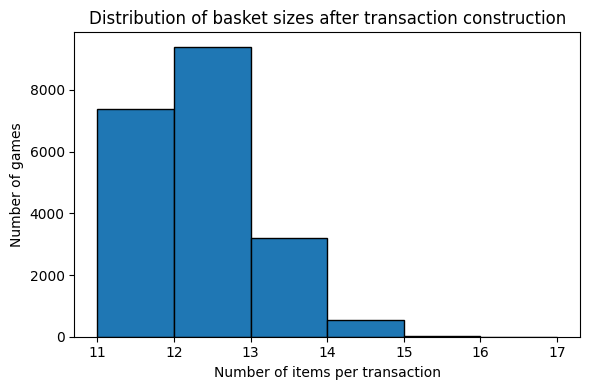

In [23]:
import matplotlib.pyplot as plt
import pandas as pd

# Compute basket sizes
basket_sizes = pd.Series([len(t) for t in transactions])

# Plot
plt.figure(figsize=(6, 4))
plt.hist(basket_sizes, bins=range(basket_sizes.min(), basket_sizes.max() + 2),
         edgecolor="black")

plt.xlabel("Number of items per transaction")
plt.ylabel("Number of games")
plt.title("Distribution of basket sizes after transaction construction")

plt.tight_layout()
plt.show()


=== Frequent itemsets vs min_support (counts) ===


,min_support,total_itemsets,k1,k2,k3,k4
0,0.01,18657,46,795,5065,12751
1,0.02,9277,45,689,3093,5450
2,0.03,5609,44,598,2059,2908
3,0.05,2581,41,428,1043,1069
4,0.08,1126,40,242,453,391
5,0.10,749,40,181,309,219


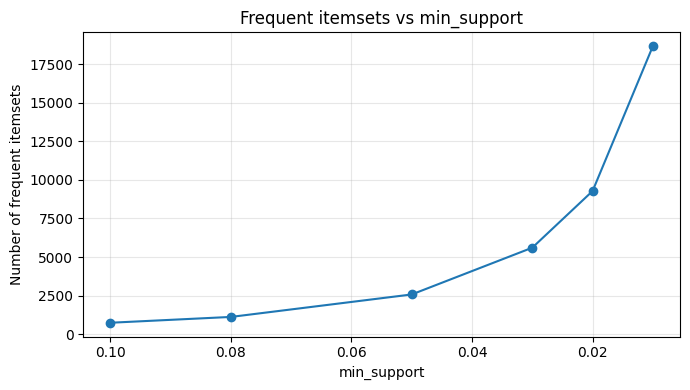

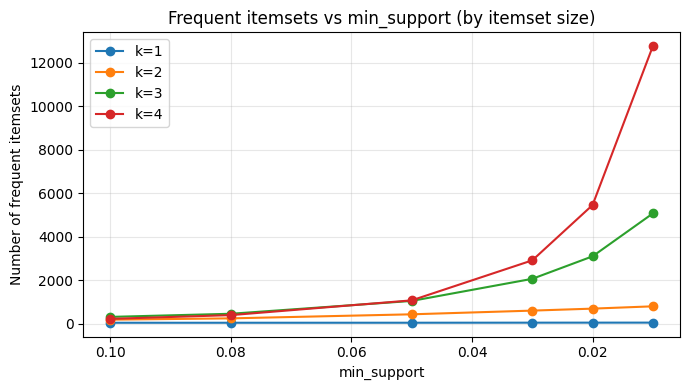

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Reuse your existing Apriori function:
# apriori_frequent_itemsets(df_onehot, min_support=..., max_len=4) -> DataFrame with columns ["itemset","k","support","count"]

# -----------------------------
# Support sweep configuration
# -----------------------------
support_values = [0.01, 0.02, 0.03, 0.05, 0.08, 0.10]
MAX_LEN = 4

rows = []
for ms in support_values:
    fi = apriori_frequent_itemsets(df_onehot, min_support=ms, max_len=MAX_LEN)
    
    # total + breakdown by k
    total = len(fi)
    counts_by_k = fi["k"].value_counts().to_dict()
    
    row = {"min_support": ms, "total_itemsets": total}
    for k in range(1, MAX_LEN + 1):
        row[f"k{k}"] = counts_by_k.get(k, 0)
    rows.append(row)

itemset_sweep = pd.DataFrame(rows).sort_values("min_support").reset_index(drop=True)

print("=== Frequent itemsets vs min_support (counts) ===")
display(itemset_sweep)

# -----------------------------
# FIGURE: #itemsets vs support
# -----------------------------
plt.figure(figsize=(7, 4))
plt.plot(itemset_sweep["min_support"], itemset_sweep["total_itemsets"], marker="o")
plt.gca().invert_xaxis()  # optional: show more patterns as support decreases (right-to-left)
plt.xlabel("min_support")
plt.ylabel("Number of frequent itemsets")
plt.title("Frequent itemsets vs min_support")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# -----------------------------
# OPTIONAL: split curves by k
# -----------------------------
plt.figure(figsize=(7, 4))
for k in range(1, MAX_LEN + 1):
    plt.plot(itemset_sweep["min_support"], itemset_sweep[f"k{k}"], marker="o", label=f"k={k}")

plt.gca().invert_xaxis()
plt.xlabel("min_support")
plt.ylabel("Number of frequent itemsets")
plt.title("Frequent itemsets vs min_support (by itemset size)")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


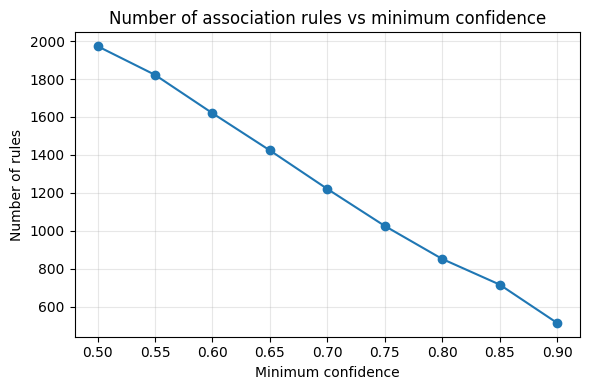

In [25]:
import numpy as np
import matplotlib.pyplot as plt

# Confidence sweep
conf_values = np.arange(0.5, 0.95, 0.05)
rule_counts = []

for c in conf_values:
    rules_tmp = generate_rules_from_frequent_itemsets(
        fi,
        support_map,
        min_conf=c,
        min_lift=1.0
    )
    rule_counts.append(len(rules_tmp))

# Plot
plt.figure(figsize=(6, 4))
plt.plot(conf_values, rule_counts, marker="o")
plt.xlabel("Minimum confidence")
plt.ylabel("Number of rules")
plt.title("Number of association rules vs minimum confidence")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


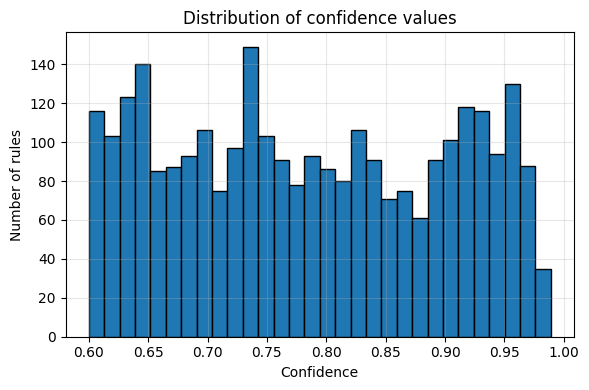

In [26]:
plt.figure(figsize=(6, 4))
plt.hist(rules_df["confidence"], bins=30, edgecolor="black")
plt.xlabel("Confidence")
plt.ylabel("Number of rules")
plt.title("Distribution of confidence values")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


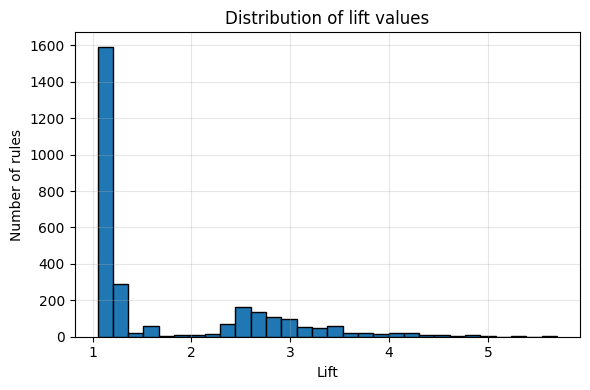

In [27]:
plt.figure(figsize=(6, 4))
plt.hist(rules_df["lift"], bins=30, edgecolor="black")
plt.xlabel("Lift")
plt.ylabel("Number of rules")
plt.title("Distribution of lift values")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
